<h1 style="text-align: center; color: white; background-color: #1e86cc; border-radius: 30px; padding: 10px;">COSC3068 - Deep Learning</h1>
<h2 style="text-align: center;">Project 1: Letter Classification</h2>
<h3 style="text-align: center;">Author: Nguyen Gia Khang</h3>
<hr />

> I declare that this submission is my own work. I have acknowledged all sources of code, pretrained models, and other materials, and disclosed any use of AI tools in accordance with the course requirements.

# I. Objective and Approach

This project is a nine-class image classification task involving grayscale patterns that resemble normalised two-dimensional Fourier spectra. The images show centred bright regions, rings, and streaks. The provided dataset contains **30,000** labelled, single-channel images, each measuring **32x32** pixels. Pixel values are represented as floating-point numbers between 0 and 1, and each image has one label in `{a, b, c, d, e, f, g, h, k}`. The task is to use the labelled images to identify the pattern class of a new image and return one of the nine permitted labels. The final classifier will be evaluated on a separate, unseen dataset with the same image format and label set.

# II. Dataset Inspection

## Dataset loading and structure


The given dataset contains 30,000 labelled images. Each image has 32 by 32 pixels and is stored as `float32`; the labels are single-character strings representing nine letter classes: `{a, b, c, d, e, f, g, h, k}`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

with np.load("student_dataset.npz") as data:
    archive_keys = data.files
    images = data["images"]
    labels = data["labels"]

class_names, class_counts = np.unique(labels, return_counts=True)

print("Archive keys:", archive_keys)
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Classes:", ", ".join(class_names))


Archive keys: ['images', 'labels']
Images: (30000, 32, 32) float32
Labels: (30000,) <U1
Classes: a, b, c, d, e, f, g, h, k


## Pixel values


The observed pixel values span 0 to 1, and every image value falls within the range specified for the dataset.


In [2]:
pixel_min = float(np.min(images))
pixel_max = float(np.max(images))
within_expected_range = bool(np.all((images >= 0) & (images <= 1)))

print(f"Minimum pixel value: {pixel_min:.3f}")
print(f"Maximum pixel value: {pixel_max:.3f}")
print("All pixels within [0, 1]:", within_expected_range)


Minimum pixel value: 0.000
Maximum pixel value: 1.000
All pixels within [0, 1]: True


## Example images


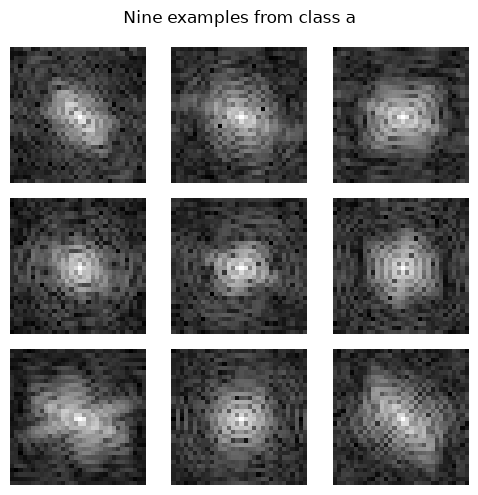

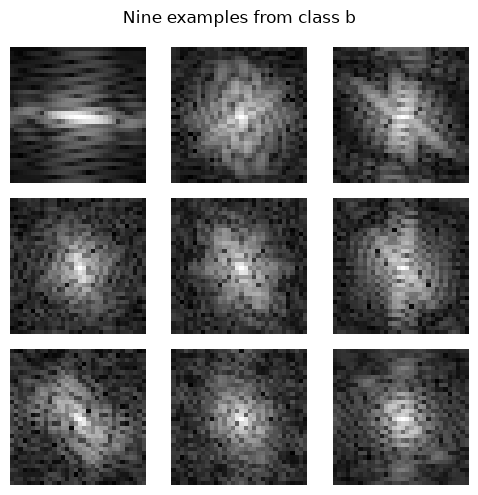

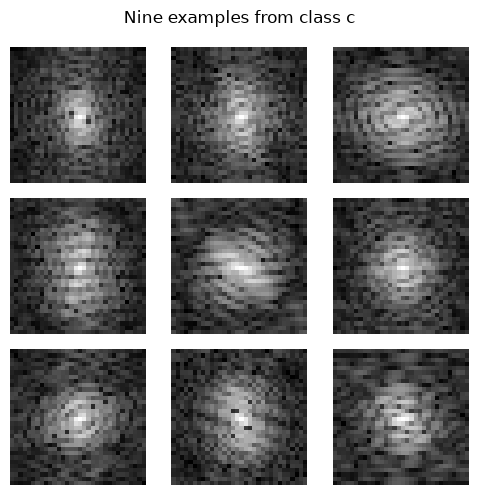

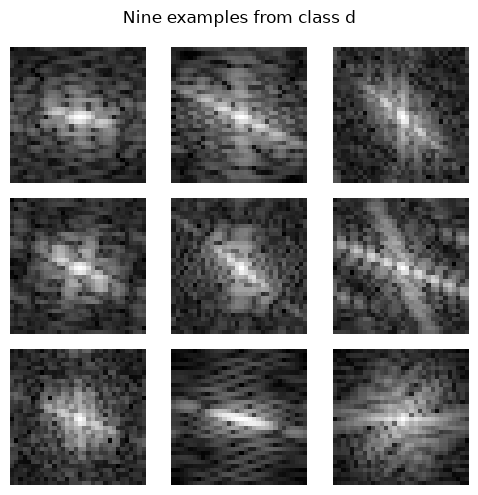

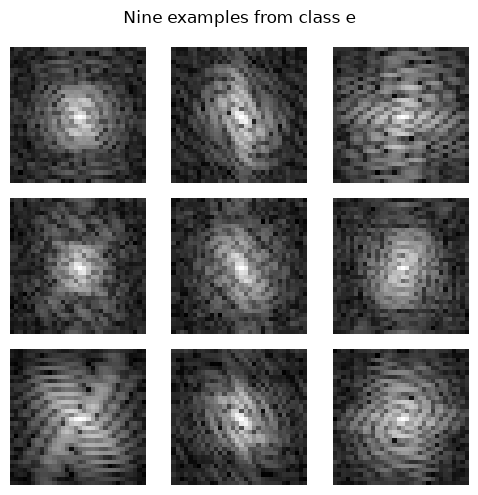

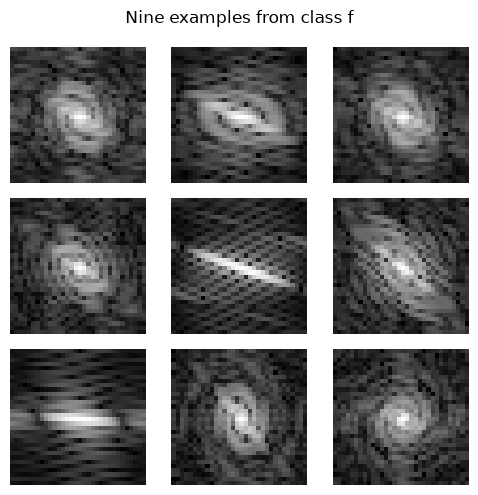

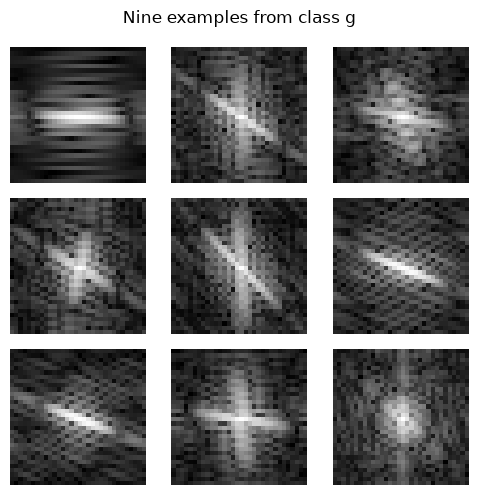

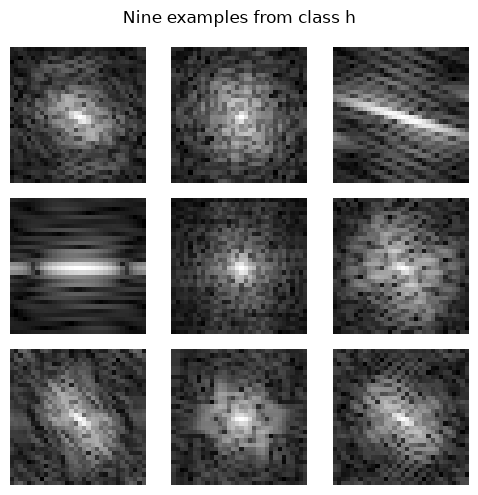

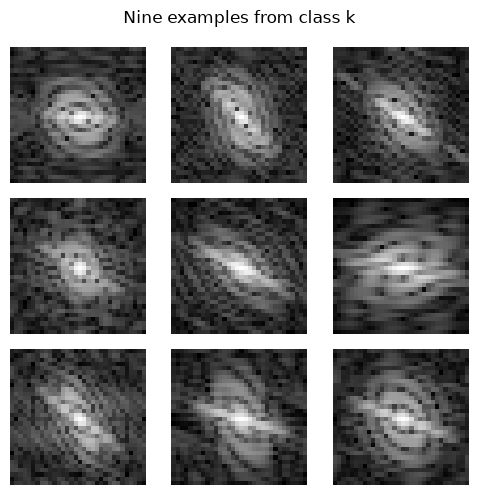

In [3]:
SEED = 42

rng = np.random.default_rng(SEED)
for label in class_names:
    candidate_indices = np.flatnonzero(labels == label)
    selected_indices = rng.choice(candidate_indices, size=9, replace=False)
    fig, axes = plt.subplots(3, 3, figsize=(5, 5))
    for ax, image_index in zip(axes.flat, selected_indices):
        ax.imshow(images[image_index], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(f"Nine examples from class {label}")
    fig.tight_layout()
    plt.show()


## Class distribution


The class counts range from **3,066** images for `e` **(10.22%)** to **3,492** images for `g` **(11.64%)**. All nine classes are represented at similar frequencies **(≈10 - 12%)**, so the dataset has no substantial class imbalance.

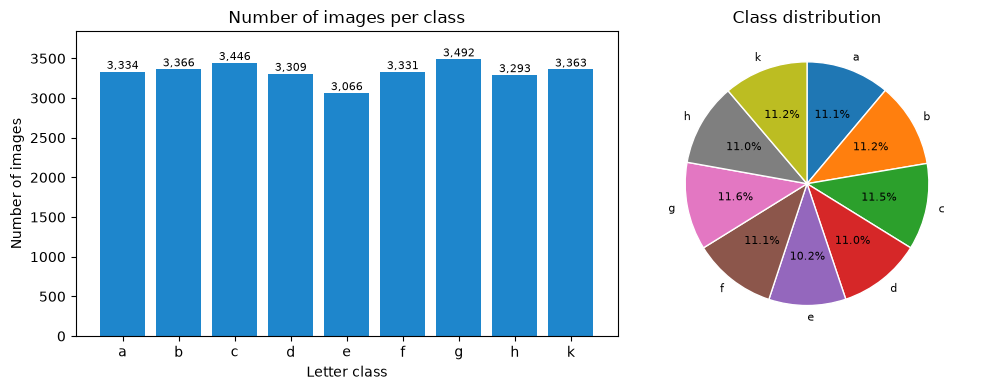

In [20]:
fig, (ax_bar, ax_pie) = plt.subplots(
    1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.6, 1]}
)
ax_bar.bar(class_names, class_counts, color="#1e86cc")
ax_bar.set_xlabel("Letter class")
ax_bar.set_ylabel("Number of images")
ax_bar.set_title("Number of images per class")
ax_bar.set_ylim(0, max(class_counts) * 1.1)
for label, count in zip(class_names, class_counts):
    ax_bar.text(label, count, f"{count:,}", ha="center", va="bottom", fontsize=8)

ax_pie.pie(
    class_counts,
    labels=class_names,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
    textprops={"fontsize": 8},
)
ax_pie.set_title("Class distribution")
ax_pie.axis("equal")

fig.tight_layout()
plt.show()


## Exact duplicate images

All 30,000 images have distinct pixel arrays, so there are no exact duplicate groups or identical images with conflicting labels. This check does not detect near-duplicates or images that look similar after small changes.

In [5]:
flat_images = images.reshape(len(images), -1)
_, image_ids, copies_per_image = np.unique(
    flat_images, axis=0, return_inverse=True, return_counts=True
)
duplicate_ids = np.flatnonzero(copies_per_image > 1)
conflicting_ids = [
    image_id for image_id in duplicate_ids
    if np.unique(labels[image_ids == image_id]).size > 1
]

print(f"Total images: {len(images)}")
print(f"Distinct images: {len(copies_per_image)}")
print(f"Exact duplicate groups: {len(duplicate_ids)}")
print(f"Groups with conflicting labels: {len(conflicting_ids)}")


Total images: 30000
Distinct images: 30000
Exact duplicate groups: 0
Groups with conflicting labels: 0


# III. Validation and Preprocessing

## Data split and rationale

The **30,000** labelled images are split into **80%** training, **10%** validation, and **10%** local holdout sets using stratified sampling and seed **42**. The training set is used to update model weights, while the validation set guides early stopping and model selection. Because repeated model weight choices can indirectly favour the validation set, the local holdout provides a separate performance check after the final configuration is fixed since it is not involved in any model training processes.

Stratified sampling keeps each class at nearly the same proportion in the training, validation, and holdout sets. This avoids accidental shifts in class balance between splits, making validation and holdout accuracy more representative of the full dataset. It preserves the original class distribution rather than correcting any imbalance in it.

In [6]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
CLASS_NAMES = np.array(["a", "b", "c", "d", "e", "f", "g", "h", "k"])
label_to_index = {label: i for i, label in enumerate(CLASS_NAMES)}
y = np.array([label_to_index[label] for label in labels], dtype=np.int32)
tf.keras.utils.set_random_seed(SEED)

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    images, y, test_size=0.1, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=1 / 9, random_state=SEED, stratify=y_dev
)

print(f"Training: {len(X_train):,}; validation: {len(X_val):,}; holdout: {len(X_holdout):,}")
print(f"{'Class':<8}{'Train %':>10}{'Val %':>10}{'Holdout %':>12}")
for class_index, label in enumerate(CLASS_NAMES):
    train_pct = 100 * np.mean(y_train == class_index)
    val_pct = 100 * np.mean(y_val == class_index)
    holdout_pct = 100 * np.mean(y_holdout == class_index)
    print(f"{label:<8}{train_pct:>9.2f}%{val_pct:>9.2f}%{holdout_pct:>11.2f}%")


Training: 24,000; validation: 3,000; holdout: 3,000
Class      Train %     Val %   Holdout %
a           11.12%    11.10%      11.10%
b           11.22%    11.23%      11.23%
c           11.48%    11.50%      11.50%
d           11.03%    11.03%      11.03%
e           10.22%    10.23%      10.23%
f           11.10%    11.10%      11.10%
g           11.64%    11.63%      11.63%
h           10.98%    10.97%      10.97%
k           11.21%    11.20%      11.20%


## Preprocessing

The images are already 32 by 32 `float32` arrays with values in [0, 1], so they are not resized or rescaled. A fixed mapping converts the nine string labels to integer targets from 0 to 8. The model's `Reshape((32, 32, 1))` layer adds the single-channel dimension, keeping the required prediction input shape `(N, 32, 32)`. Data augmentation will be included as model layers so they can run alongside training computations and use GPU acceleration when a GPU is available. These layers are active during training and inactive during validation, local holdout evaluation, and deployment predictions.

## Leakage prevention

To prevent leakage, the original images are split before augmentation or any **data-dependent** preprocessing steps. If augmented copies are created first and then split, versions of the same source image could appear in both training and validation or holdout sets, inflating measured accuracy. Only training images and labels update model weights, and random augmentation runs only during fitting; validation and holdout images remain unaltered. Validation data guides early stopping and model selection, so its results are not treated as an independent final score. Prediction results are evaluated on the holdout set once after the final model configuration is fixed.

# IV. Model Architecture

# V. Training Methodology

# VI. Experiments and Results

# VII. Evaluation and Error Analysis

# VIII. Reflection and Reproducibility

# IX. Sources and Acknowledgements